In [23]:
import pandas as pd
import numpy as np

from google.colab import files

uploaded = files.upload()

# Membaca file menggunakan read_csv karena format file yang diunggah adalah .csv
df = pd.read_csv(next(iter(uploaded)))

print("Ukuran data:", df.shape)
display(df.head())

Saving insurance.csv to insurance (4).csv
Ukuran data: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [24]:
# Mengambil 100 sampel secara acak
data_100 = df["charges"].sample(
    n=100,
    random_state=42
).reset_index(drop=True)

data = data_100.to_numpy()

print("Jumlah sampel:", len(data))
display(data_100.head())

Jumlah sampel: 100


,charges
0,9095.06825
1,5272.17580
2,29330.98315
3,9301.89355
4,33750.29180


A.) Estimasi titik dan interval distribusi Z
Tingkat kesalahan 5% dan tingkat kepercayaan 95%.

In [25]:
n = len(data)

# Estimasi titik
mean = np.mean(data)
std = np.std(data, ddof=1)

# Distribusi Z
z = 1.96

se = std / np.sqrt(n)

bawah = mean - z * se
atas = mean + z * se

print("ESTIMASI TITIK DAN INTERVAL")
print("Rata-rata:", mean)
print("Standar deviasi:", std)
print("Nilai Z:", z)
print("Batas bawah:", bawah)
print("Batas atas:", atas)
print("Interval kepercayaan:", bawah, "-", atas)

ESTIMASI TITIK DAN INTERVAL
Rata-rata: 13807.148351900003
Standar deviasi: 12532.729136069463
Nilai Z: 1.96
Batas bawah: 11350.733441230388
Batas atas: 16263.563262569618
Interval kepercayaan: 11350.733441230388 - 16263.563262569618


B.) 1. Resampling metode Jackknife


In [26]:
jackknife = []

for i in range(n):
    sampel = np.delete(data, i)
    jackknife.append(np.mean(sampel))

rata_jackknife = np.mean(jackknife)

print("HASIL JACKKNIFE")
print("Jumlah resampling:", len(jackknife))
print("Rata-rata Jackknife:", rata_jackknife)

HASIL JACKKNIFE
Jumlah resampling: 100
Rata-rata Jackknife: 13807.148351900003


B.) 2.  Resampling metode Bootstrapping (1.000 iterasi)

In [27]:
B = 1000

bootstrap = []

np.random.seed(42)

for i in range(B):
    sampel = np.random.choice(
        data,
        size=n,
        replace=True
    )

    bootstrap.append(np.mean(sampel))

rata_bootstrap = np.mean(bootstrap)

print("HASIL BOOTSTRAPPING")
print("Jumlah iterasi:", B)
print("Rata-rata Bootstrap:", rata_bootstrap)

HASIL BOOTSTRAPPING
Jumlah iterasi: 1000
Rata-rata Bootstrap: 13799.3988989255


In [28]:
hasil = pd.DataFrame({
    "Metode": [
        "Estimasi Titik",
        "Jackknife",
        "Bootstrapping"
    ],
    "Rata-rata": [
        mean,
        rata_jackknife,
        rata_bootstrap
    ]
})

display(hasil)

,Metode,Rata-rata
0,Estimasi Titik,13807.148352
1,Jackknife,13807.148352
2,Bootstrapping,13799.398899


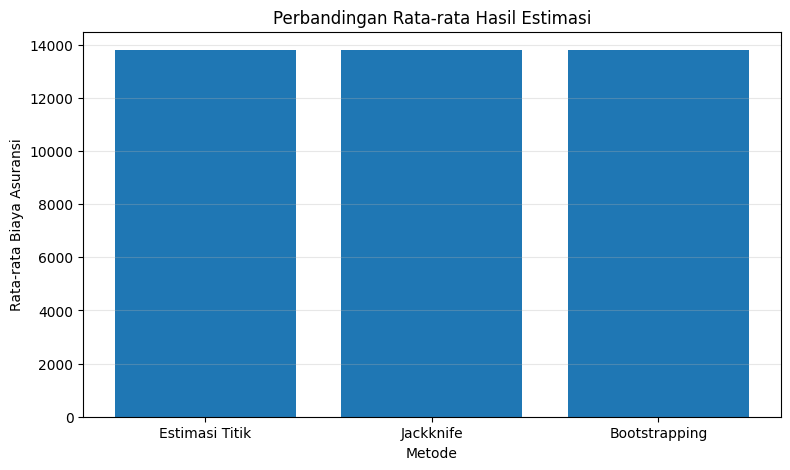

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

metode = [
    "Estimasi Titik",
    "Jackknife",
    "Bootstrapping"
]

nilai = [
    mean,
    rata_jackknife,
    rata_bootstrap
]

plt.bar(metode, nilai)

plt.title("Perbandingan Rata-rata Hasil Estimasi")
plt.xlabel("Metode")
plt.ylabel("Rata-rata Biaya Asuransi")

plt.grid(axis="y", alpha=0.3)
plt.show()

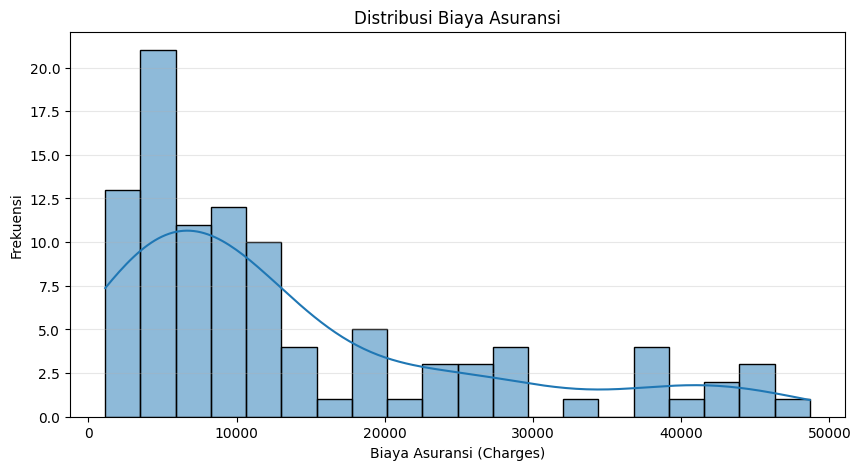

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(data, bins=20, kde=True)

plt.title("Distribusi Biaya Asuransi")
plt.xlabel("Biaya Asuransi (Charges)")
plt.ylabel("Frekuensi")
plt.grid(axis="y", alpha=0.3)

plt.show()
